In [20]:
# Core scverse libraries
from __future__ import annotations

import anndata as ad

# Data retrieval
import pooch
import scanpy as sc

AnnData est une bibliothèque (et une structure de données) Python indépendante, conçue spécifiquement pour gérer des matrices de données tabulaires annotées à grande échelle, avec un focus particulier sur la génomique et le single-cell.

pooch est un utilitaire de téléchargement et de gestion de cache.

scanpy est la bibliothèque principale de traitement et d'analyse de données single-cell.

In [21]:
import sys
print(sys.executable)

/home/amalet/venvs/scanpy/bin/python3


In [22]:
sc.set_figure_params(dpi=50, facecolor="white")

In [4]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("scverse_tutorials"),
    base_url="doi:10.6084/m9.figshare.22716739.v1/",
)
EXAMPLE_DATA.load_registry_from_doi()

In [23]:
samples = {
    "s1d1": "s1d1_filtered_feature_bc_matrix.h5",
    "s1d3": "s1d3_filtered_feature_bc_matrix.h5",
}
adatas = {}

for sample_id, filename in samples.items():
    path = EXAMPLE_DATA.fetch(filename)
    sample_adata = sc.read_10x_h5(path)
    sample_adata.var_names_make_unique()
    adatas[sample_id] = sample_adata

adata = ad.concat(adatas, label="sample")
adata.obs_names_make_unique()
print(adata.obs["sample"].value_counts())
adata

/home/amalet/venvs/scanpy/lib64/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


sample
s1d1    8785
s1d3    8340
Name: count, dtype: int64


/home/amalet/venvs/scanpy/lib64/python3.14/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/tmp/ipykernel_1576/3491096135.py:13: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  adata = ad.concat(adatas, label="sample")


AnnData object with n_obs × n_vars = 17125 × 36601
    obs: 'sample'
    layers: None (.X)

### Mitochondrial / Ribosomal / Hemoglobin genes
* **Mitochondrie :** Contrôle la santé des cellules, chercher des signes d'apoptose.
* **Ribosomes :** Chercher des signes d'activité traductionnelle, métabolique.
* **Hémoglobine :** Détection de contamination sanguine.


In [25]:
# mitochondrial genes, "MT-" for human, "Mt-" for mouse
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes Ribosomal Protein Small subunit, Ribosomal Protein Large subunit
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes. La regex "^HB[^(P)]": "Trouve les gènes commençant par HB, suivis de n'importe quel caractère, à condition que ce caractère ne soit pas un P".
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

Rappel sur les [  ]: Tout y est considéré par défaut comme un simple caractère, sauf de très rares exceptions (comme le tiret pour les plages a-z ou le ^ pour inverser la sélection).

Adding QC variables to the adata dataset with scanpy sc.pp.calculate_qc_metrics().

In [27]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)  # pp: pre-processing

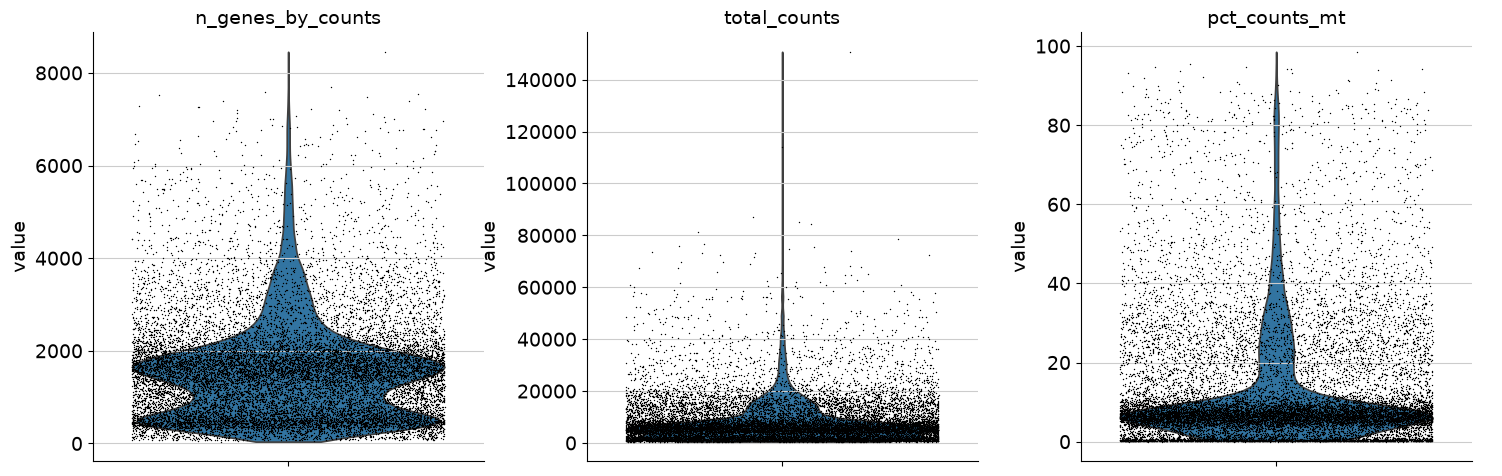

In [28]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
) # pl: plotting

**n_genes_by_counts :** Le nombre de gènes différents (uniques) qui ont été détectés au moins une fois dans la cellule.

**total_counts :** Le nombre total de molécules d'ARN (ou UMI) séquencées et comptées dans la cellule.

**pct_counts_mt :** La proportion de molécules d'ARN (ou de comptes) provenant des gènes du génome mitochondrial par rapport au nombre total de molécules d'ARN détectées dans la cellule.

À partir des graphiques des indicateurs de contrôle qualité, il est désormais possible d’éliminer les cellules présentant un nombre trop élevé de gènes mitochondriaux exprimés ou un nombre total trop élevé de gènes, en définissant des seuils manuels ou automatiques. Cependant, ce qui semble être de mauvais indicateurs de contrôle qualité peut parfois s’expliquer par des phénomènes biologiques réels ; nous suggérons donc de commencer par une stratégie de filtrage très souple et de la réexaminer ultérieurement. Nous ne filtrons donc désormais que les cellules exprimant moins de 100 gènes et celles dans lesquelles les gènes sont détectés dans moins de 3 cellules.

**Pourquoi filtrer les cellules avec un nombre trop élevé de gènes mitochondriaux?:** Lorsqu'une cellule commence à mourir (cellules endommagées, nécrotiques ou lysées), sa membrane plasmique se fragilise et commence à fuir. Comme l'ARN cytoplasmique libre s'échappe de la cellule endommagée et est perdu, alors que l'ARN mitochondrial reste en grande partie piégé à l'intérieur des organites mitochondriaux (qui persistent dans les débris), la proportion relative de transcripts mitochondriaux augmente mécaniquement dans le profil de la cellule. Un _pourcentage élevé_ de _pct_counts_mt_ est donc le marqueur classique d'une cellule lysée ou en train de mourir.

**Pourquoi filtrer les cellules avec un nombre trop élevé de gènes?:** Un nombre anormalement haut de gènes (la longue queue tout en haut du premier graphique) est généralement le signe d'un artéfact technique majeur : les doublets (ou multiplets). Lors de la capture (sur 10X Genomics par exemple), il arrive statistiquement qu'une micro-gouttelette capture deux cellules (ou plus) au lieu d'une seule. Le séquenceur lit le contenu des deux cellules en même temps. Le profil obtenu combine l'ARN de la cellule A et de la cellule B. Cela se traduit par un nombre total de comptes (total_counts) et un nombre de gènes uniques (n_genes_by_counts) anormalement élevés.


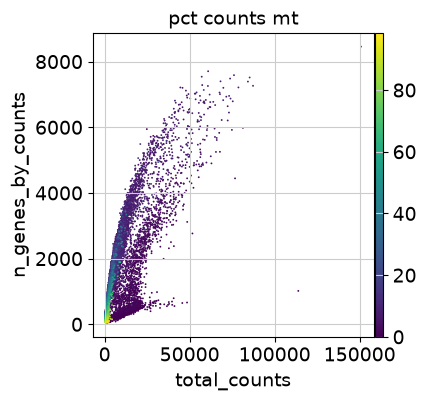

In [29]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

**Points en bas à gauche:** Ce sont typiquement des débris cellulaires, des "gouttelettes vides" ou des cellules en train de mourir/lysées. Le peu d'ARN qu'il reste dedans provient presque exclusivement de leurs mitochondries, ce qui fait exploser le pourcentage mitochondrial alors que le total général d'ARN est minime.

**La diagonale principale (en hauteur) :** La grande majorité des cellules saines s'aligne le long de cette courbe ascendante. Plus une cellule a de molécules d'ARN (total_counts), plus elle exprime de gènes différents (n_genes_by_counts), ce qui est tout à fait normal. Ces cellules sont violet foncé, ce qui signifie qu'elles ont un faible taux de mitochondries (donc saines).

**Les points extrêmes (en haut à droite ou isolés) :** Les cellules très éloignées avec énormément de comptes et de gènes (vers 100 000+ sur l'axe des x) correspondent généralement à des doublets (plusieurs cellules capturées dans la même gouttelette).

Pour les datasets avec plusieurs batchs, faire un preprocessing pour chaque batch, la variabilité inter-échantillons pouvant être importante.

In [30]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)

**Détection des doublets :** L'outil Scrublet de scanpy détecte les doublet par une méthode de KNN observed-transcriptome/simulated-doublets. On peut filtrer directement avec predicted_doublets() ou regarder le doublet_score() pour le faire après à la main.

In [31]:
sc.pp.scrublet(adata, batch_key="sample")

**Normalisation :** L'étape suivante consiste à normaliser les données pour qu'elles soient comparables.
On utilise pour cela une méthode en deux temps :

    On ajuste la taille de chaque cellule pour qu'elles aient toutes le même nombre total de molécules (en se basant sur une valeur de référence, comme la médiane du groupe ou un chiffre fixe comme 10 000, qu'on règle avec l'option target_sum).

    On lisse les chiffres avec un outil mathématique (log1p) pour éviter que certains gènes aux scores gigantesques ne bloquent l'ordinateur.

Ce combo de nettoyage s'appelle le log1PF.

In [32]:
# Saving count data
adata.layers["counts"] = adata.X.copy()

In [38]:
adata.layers["counts"]

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 26539065 stored elements and shape (17041, 23427)>

In [17]:
adata

AnnData object with n_obs × n_vars = 17041 × 23427
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scrublet'
    layers: None (.X), 'counts'

In [18]:
# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)

In [19]:
adata

AnnData object with n_obs × n_vars = 17041 × 23427
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scrublet', 'log1p'
    layers: None (.X), 'counts'

**Feature selection:** We want to _reduce the dimensionality_ of the dataset and only include the _most informative genes_. This step is commonly known as feature selection.

In [20]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample")

**Quels sont les 2000 gènes (*n_top_genes*) qui varient le plus d'une cellule à l'autre (*sample*) et qui vont m'aider à distinguer les différents types cellulaires?**

**En abscisse (X) :** La moyenne de l'expression des gènes (mean expressions of genes). Plus on va vers la droite, plus le gène est exprimé en moyenne dans l'ensemble des cellules.

**En ordonnée (Y) :** La dispersion (une mesure de la variance/dispersion de l'expression du gène d'une cellule à l'autre). Plus un gène est haut, plus son expression varie fortement d'une cellule à l'autre.

**Points noirs :** Les gènes hautement variables (highly variable genes) sélectionnés par Scanpy. Ce sont ceux qu'on va garder pour faire le clustering, l'ACP (PCA) et le t-SNE/UMAP.

**Points gris :** Les autres gènes (other genes), considérés comme moins informatifs (soit trop constants, soit trop bruités par rapport à leur moyenne), qui vont être ignorés pour la suite.

**Standardisation :** La dispersion y est standardisée ("normalisée") par rapport au niveau d'expression moyen. Les points noirs (sélectionnés) sont ceux qui dépassent un certain seuil de dispersion normalisée vers le haut. C'est ce groupe de gènes "au-dessus du lot" qui est conservé.

- Le regroupement par "bins" (intervalles) d'expression :
Scanpy prend tous les gènes et les classe par catégories selon leur expression moyenne (axe X).

- Le calcul de la dispersion attendue :
Pour chaque groupe de gènes qui ont le même niveau d'expression moyen, Scanpy calcule la moyenne et la variance de leur dispersion brute. Cela permet de définir une "courbe de tendance" (combien de dispersion on s'attend normalement à avoir pour un gène qui a cette expression moyenne-là).

- La standardisation (formule générale) :
Pour chaque gène, la dispersion normalisée est obtenue en prenant sa dispersion brute, en lui soustrayant la dispersion moyenne attendue pour son groupe, puis en divisant le tout par l'écart-type de la dispersion de ce même groupe.

- On rappelle la formule pour ceux qui sont nuls en stats (normalisation centrée-réduite):  $\frac{X_i - \bar{x}_{groupe}}{\sigma_{groupe}}$.  
"Elle mesure à combien d'écarts-types ($\sigma$) une valeur ($Xi$) se trouve par rapport à la moyenne ($\bar{x}$)."

- Cette transformation ramène à $N(0;1)$ ($\bar{x} = 0$, $\sigma = 1$), d'où le terme de "Normalisation", mais la position des quartiles ne change pas car toutes les valeurs subissent exactement la même opération linéaire.

Dans Scanpy, on cherche un écart par rapport à la moyenne divisé par une mesure de dispersion, mais le calcul est appliqué par tranche d'expression moyenne pour chaque gène, et non sur l'ensemble global des cellules d'un coup, afin d'éviter le biais lié au fait que les gènes très exprimés varient naturellement plus.

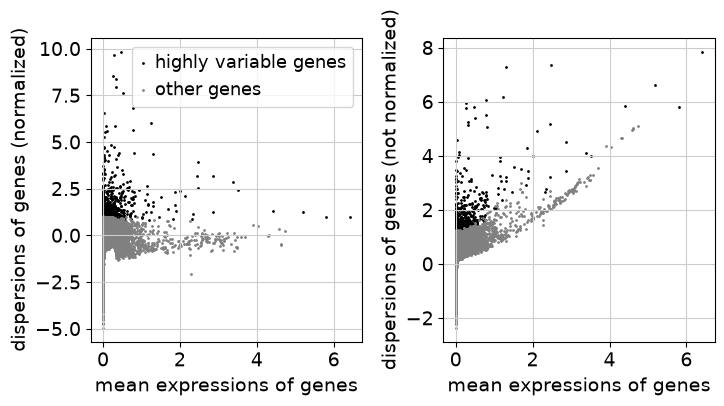

In [21]:
sc.pl.highly_variable_genes(adata)